# Dataset generation

Choose the input bounds and airfoils below. Latin hypercube sampling creates
`n_samples` cases, which run in CPU processes. The notebook saves results in DOE order.

| Input | Meaning / units |
| --- | --- |
| `aspect_ratio` | Full-wing aspect ratio |
| `area_m2` | Full-wing planform area, m^2 |
| `taper_ratio` | Tip chord / root chord |
| `tip_twist_deg` | Tip twist relative to the root, degrees |
| `alpha_deg` | Angle of attack, degrees |
| `velocity` | Freestream velocity, m/s |
| `airfoil` | Symmetric airfoil geometry selected from `airfoils` |

Root twist and sweep are fixed at zero. Twist varies linearly to the tip;
negative tip twist is washout. Equal bounds hold any numeric input fixed.

Reynolds number is calculated as `Re = velocity * chord / kinematic_viscosity`
using the solver's default atmosphere. It is not an independent input. The CSV
includes a derived `reynolds` value based on mean aerodynamic chord; the solver
uses local chord to calculate Reynolds number at each station.


In [ ]:
import sys
from pathlib import Path

project_path = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(project_path / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import qmc
from joblib import Parallel, delayed, effective_n_jobs, parallel_config

from solver.geometry import WingParameters, build_wing_geometry
from solver.vlm import solve_vlm_neuralfoil

data_path = project_path / "data"
data_path.mkdir(exist_ok=True)


In [ ]:
# Numeric input bounds: (minimum, maximum).
doe_bounds = {
    "aspect_ratio": (4.0, 16.0),
    "area_m2": (0.5, 10.0),
    "taper_ratio": (0.2, 0.5),
    "tip_twist_deg": (-3.0, 0.0),
    "alpha_deg": (2.0, 6.0),
    "velocity": (40.0, 100.0),
}
airfoils = ["naca0012", "naca0015"]  # Example: ["naca0012", "naca0015"].

n_samples = 500
seed = 10

solver_options = {
    "spanwise_resolution": 40,
    "chordwise_resolution": 4,
    "lift_tolerance": 1e-6,
}
output_path = data_path / "wing_data_trial.csv"


In [ ]:
# Sample numeric inputs and use the final dimension to select an airfoil.
sampler = qmc.LatinHypercube(d=len(doe_bounds) + 1, seed=seed)
samples = sampler.random(n=n_samples)

doe = pd.DataFrame({
    name: lower + samples[:, i] * (upper - lower)
    for i, (name, (lower, upper)) in enumerate(doe_bounds.items())
})
doe["airfoil"] = [airfoils[int(value * len(airfoils))] for value in samples[:, -1]]

print(f"Latin hypercube DOE: {len(doe)} cases.")
doe


In [ ]:
# -2: all CPUs except one; -1: all CPUs; 1: serial; or choose a worker count.
n_jobs = -2


def solve_case(case_id, case, solver_options):
    from solver.geometry import WingParameters, build_wing_geometry
    from solver.vlm import solve_vlm_neuralfoil

    parameters = WingParameters(
        aspect_ratio=case["aspect_ratio"],
        area_m2=case["area_m2"],
        taper_ratio=case["taper_ratio"],
        tip_twist_deg=case["tip_twist_deg"],
        airfoil=case["airfoil"],
        sweep_deg=0.0,
    )
    geometry = build_wing_geometry(parameters)
    result = solve_vlm_neuralfoil(
        geometry,
        alpha=case["alpha_deg"],
        velocity=case["velocity"],
        **solver_options,
    )

    return {
        "case_id": case_id,
        "geometry_id": geometry.geometry_id,
        **case.to_dict(),
        "reynolds": result["reynolds"],  # Derived from velocity and mean aerodynamic chord.
        "CL": result["CL"],
        "CD_profile": result["CD_profile"],
        "max_lift_error": result["max_lift_error"],
        "runtime_s": result["total_runtime_s"],
    }


In [ ]:
rows = []

# Keep one numerical-library thread per worker to avoid CPU oversubscription.
with parallel_config(backend="loky", inner_max_num_threads=1):
    with Parallel(
        n_jobs=min(effective_n_jobs(n_jobs), len(doe)),
        return_as="generator", batch_size=1,
    ) as parallel:
        results = parallel(
            delayed(solve_case)(case_id, case, solver_options)
            for case_id, case in doe.iterrows()
        )
        for row in results:
            rows.append(row)
            df = pd.DataFrame(rows)
            df.to_csv(output_path, index=False)
            print(f"Completed {len(rows)}/{len(doe)}: CL = {row['CL']:.4f}")

df


# Plots for Data Visualization

Each point is one DOE case. Multiple inputs can vary between points.


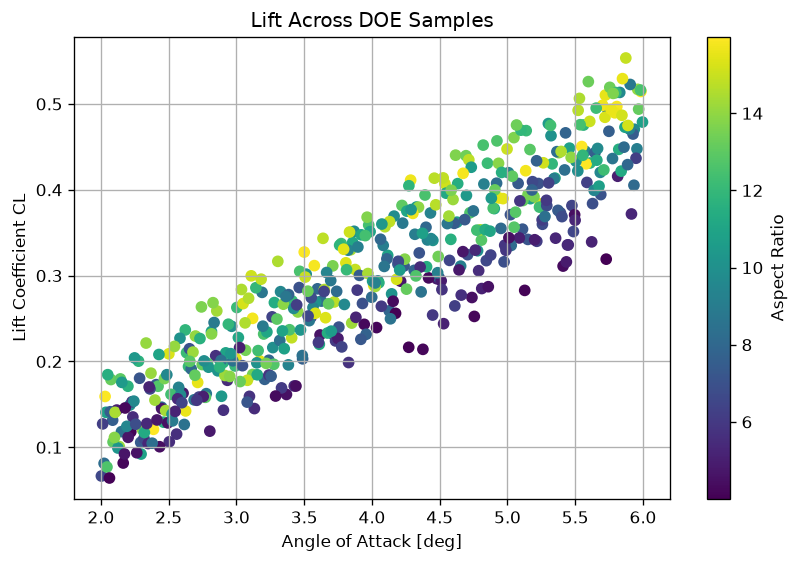

In [1]:
plt.figure(figsize=(8, 5))
plt.scatter(df["alpha_deg"], df["CL"], c=df["aspect_ratio"], cmap="viridis")
plt.colorbar(label="Aspect Ratio")
plt.xlabel("Angle of Attack [deg]")
plt.ylabel("Lift Coefficient CL")
plt.title("Lift Across DOE Samples")
plt.grid()
plt.show()


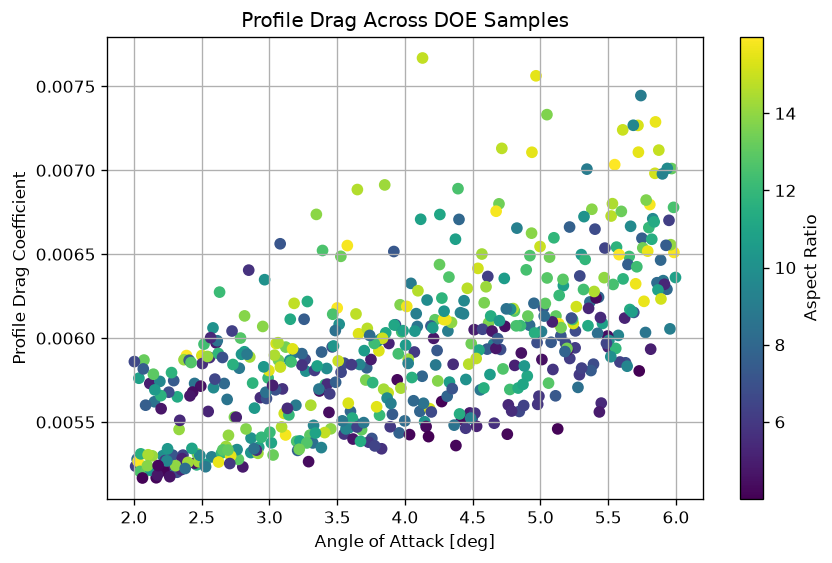

In [2]:
plt.figure(figsize=(8, 5))
plt.scatter(df["alpha_deg"], df["CD_profile"], c=df["aspect_ratio"], cmap="viridis")
plt.colorbar(label="Aspect Ratio")
plt.xlabel("Angle of Attack [deg]")
plt.ylabel("Profile Drag Coefficient")
plt.title("Profile Drag Across DOE Samples")
plt.grid()
plt.show()


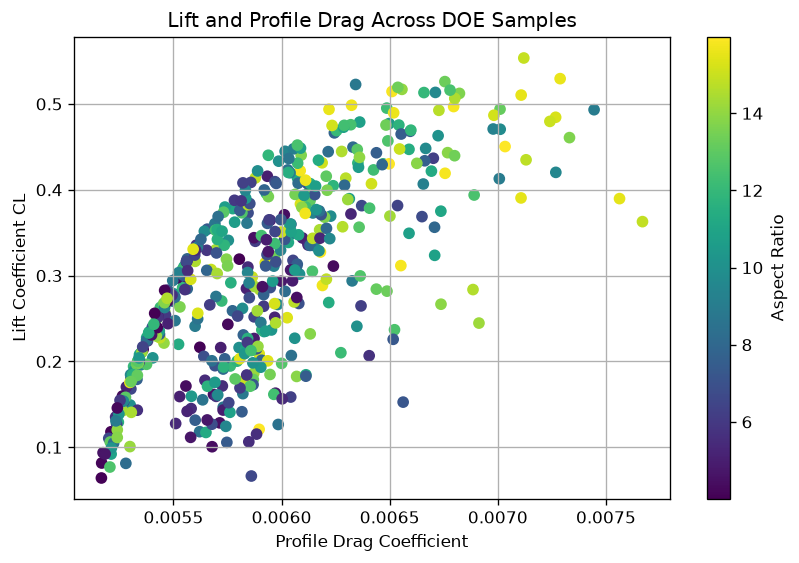

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(df["CD_profile"], df["CL"], c=df["aspect_ratio"], cmap="viridis")
plt.colorbar(label="Aspect Ratio")
plt.xlabel("Profile Drag Coefficient")
plt.ylabel("Lift Coefficient CL")
plt.title("Lift and Profile Drag Across DOE Samples")
plt.grid()
plt.show()
